In [1]:
import unyts
import pandas as pd
import seaborn as sns
import numpy as np
import time


In [3]:
unyts.database.database_size()

(3141, 6282, 325)

In [4]:
unyts.database._load_complete_database()

Setting UNYTS_MAX_COMBINATIONS to infinity for complete database load.
UNYTS_MAX_COMBINATIONS value: inf
Database size before: (3141, 6282, 325)


Complete database loaded.
Database size after: (1820357, 3640714, 2006)


In [5]:
unyts.database.database_size()

(1820357, 3640714, 2006)

In [10]:
from unyts.errors import NoConversionFoundError
import time

def meassure_conversion_time(from_unit:str, to_unit:str, value=1):
    _KeyError = True
    _attempts = 0
    _max_attempts = 100
    while _KeyError:
        start_time = time.perf_counter()
        error = False
        _KeyError = False
        try:
            _ = unyts.convert(value, from_unit, to_unit)
        except NoConversionFoundError:
            error = True
        except KeyError:
            if _attempts >= _max_attempts:
                print(f"** Maximum attempts reached for conversion from {from_unit} to {to_unit}. Aborting.")
                _KeyError = False
            else:
                _KeyError = True
                _attempts += 1
                time.sleep(1)
                print(f"KeyError encountered while converting from {from_unit} to {to_unit}. Retrying... Attempt {_attempts}.{' '*50}", end='\r')
        end_time = time.perf_counter()
        
    if error:
        print(f"-> Conversion from {from_unit} to {to_unit} failed using engine {unyts.get_engine()} and algorithm {unyts.get_algorithm()}.{' '*50}", end='\r')

    return end_time - start_time, error

def meassure_all_conversions(units_dic:dict=unyts.dictionaries.dictionary, rept=1, algorithm=["BFS", "lean_BFS", "cpp", "DFS"], results:dict=None):
    unyts_algorithm_backup = unyts.get_algorithm()
    unyts_engine_backup = unyts.get_engine()
    unyts.print_path(False)
    unyts.cache(False)
    if type(algorithm) is str:
        algorithm = [algorithm]
    if results is None:
        results = {}  # Store results for each pair converted for each algorithm

    for key in units_dic:
        print(f"Measuring conversions for key: {key}")
        units = units_dic.get(key, [])
        for f in range(len(units)):
            for t in range(f + 1, len(units)):
                from_unit = units[f]
                to_unit = units[t]
                time_BFS = float('inf')
                time_lean_BFS = float('inf')
                for algo in algorithm:
                    if algo == 'cpp':
                        unyts.set_engine('cpp')
                        unyts.set_algorithm('hybrid_BFS')
                    else:
                        unyts.set_engine('python')
                        unyts.set_algorithm(algo)
                    for r in range(rept):
                        time_taken, error = meassure_conversion_time(from_unit, to_unit)
                        results[(key, from_unit, to_unit, algo, r)] = (time_taken, error)
                        if algo == 'BFS':
                            time_BFS = time_taken
                        elif algo == 'lean_BFS':
                            time_lean_BFS = time_taken
                        if time_BFS > time_lean_BFS and time_lean_BFS != float('inf') and time_BFS != float('inf'):
                            print(f"Lean BFS {time_lean_BFS} is faster than BFS {time_BFS} for conversion from {from_unit} to {to_unit}")
    unyts.set_algorithm(unyts_algorithm_backup)
    unyts.set_engine(unyts_engine_backup)
    unyts.cache(True)
    return results

In [11]:
keep_results = {}
results = meassure_all_conversions(algorithm=["BFS", "lean_BFS", 'cpp'], rept=5, results=keep_results)

Measuring conversions for key: Time
Lean BFS 0.005890199972782284 is faster than BFS 0.006336399994324893 for conversion from years to WE                                                  
Lean BFS 0.007810299983248115 is faster than BFS 0.008847000019159168 for conversion from years to DAY
Lean BFS 0.007810299983248115 is faster than BFS 0.008847000019159168 for conversion from years to DAY
Lean BFS 0.007810299983248115 is faster than BFS 0.008847000019159168 for conversion from years to DAY
Lean BFS 0.007810299983248115 is faster than BFS 0.008847000019159168 for conversion from years to DAY
Lean BFS 0.007810299983248115 is faster than BFS 0.008847000019159168 for conversion from years to DAY
Lean BFS 0.007810299983248115 is faster than BFS 0.008847000019159168 for conversion from years to DAY
Lean BFS 0.004275099956430495 is faster than BFS 0.006669600028544664 for conversion from MONTHS to day                                       
Lean BFS 0.002806500007864088 is faster than BFS 0.

KeyboardInterrupt: 

In [12]:
keep_results


{('Time', 'HR', 'Wh/W', 'BFS', 0): (0.0008426999556832016, False),
 ('Time', 'HR', 'Wh/W', 'BFS', 1): (0.0006363000138662755, False),
 ('Time', 'HR', 'Wh/W', 'BFS', 2): (0.0006284999544732273, False),
 ('Time', 'HR', 'Wh/W', 'BFS', 3): (0.0006181999924592674, False),
 ('Time', 'HR', 'Wh/W', 'BFS', 4): (0.0006195000023581088, False),
 ('Time', 'HR', 'Wh/W', 'lean_BFS', 0): (0.011732499988283962, False),
 ('Time', 'HR', 'Wh/W', 'lean_BFS', 1): (0.012191499990876764, False),
 ('Time', 'HR', 'Wh/W', 'lean_BFS', 2): (0.016024200012907386, False),
 ('Time', 'HR', 'Wh/W', 'lean_BFS', 3): (0.013997200003359467, False),
 ('Time', 'HR', 'Wh/W', 'lean_BFS', 4): (0.022394099971279502, False),
 ('Time', 'HR', 'Wh/W', 'cpp', 0): (0.0009239999926649034, True),
 ('Time', 'HR', 'Wh/W', 'cpp', 1): (0.000859999970998615, True),
 ('Time', 'HR', 'Wh/W', 'cpp', 2): (0.0007790999952703714, True),
 ('Time', 'HR', 'Wh/W', 'cpp', 3): (0.0008159000426530838, True),
 ('Time', 'HR', 'Wh/W', 'cpp', 4): (0.000624500

In [13]:
unyts.convert(1, 'deg C', 'DEGREES R')

493.46999999999997

In [14]:
r = pd.DataFrame.from_dict(keep_results, orient='index', columns=['time_taken', 'error'])
r[['key', 'from_unit', 'to_unit', 'alg', 'ite']] = pd.DataFrame(r.index.tolist(), index=r.index)
r.reset_index(drop=True, inplace=True)
r['from_to'] = r['from_unit'] + '->' + r['to_unit']

In [15]:
r

,time_taken,error,key,from_unit,to_unit,alg,ite,from_to
0,0.000843,False,Time,HR,Wh/W,BFS,0,HR->Wh/W
1,0.000636,False,Time,HR,Wh/W,BFS,1,HR->Wh/W
2,0.000628,False,Time,HR,Wh/W,BFS,2,HR->Wh/W
3,0.000618,False,Time,HR,Wh/W,BFS,3,HR->Wh/W
4,0.000620,False,Time,HR,Wh/W,BFS,4,HR->Wh/W
...,...,...,...,...,...,...,...,...
135388,0.000936,True,TemperatureGradient,"deg C/""",degr/zm,cpp,3,"deg C/""->degr/zm"
135389,0.000927,True,TemperatureGradient,"deg C/""",degr/zm,cpp,4,"deg C/""->degr/zm"
135390,0.000114,False,TemperatureGradient,"deg C/""",DEGC/METRE,BFS,0,"deg C/""->DEGC/METRE"
135391,0.000078,False,TemperatureGradient,"deg C/""",DEGC/METRE,BFS,1,"deg C/""->DEGC/METRE"


<Axes: xlabel='from_to', ylabel='time_taken'>

d:\git\unyts\.venv\Lib\site-packages\IPython\core\events.py:100: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)
d:\git\unyts\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


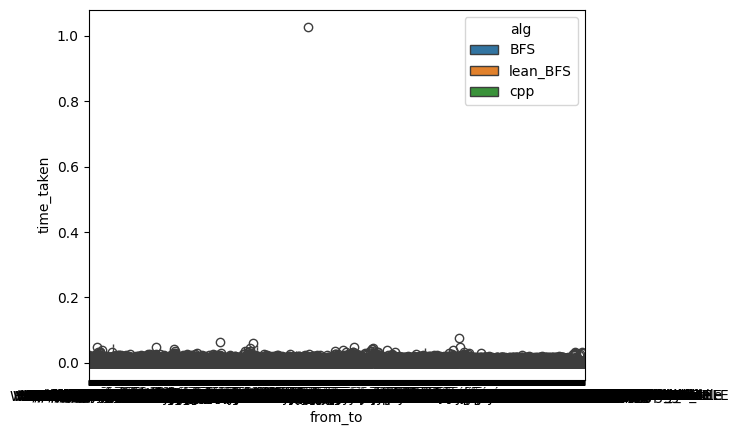

In [16]:
sns.boxplot(data=r, x='from_to', y='time_taken', hue='alg')

<Axes: xlabel='alg', ylabel='time_taken'>

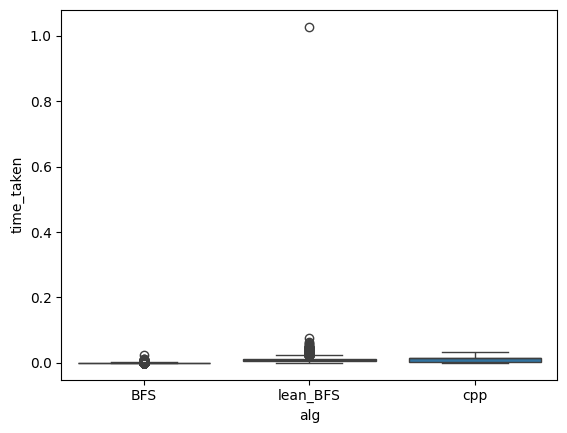

In [17]:
sns.boxplot(data=r, x='alg', y='time_taken')

<Axes: xlabel='alg', ylabel='time_taken'>

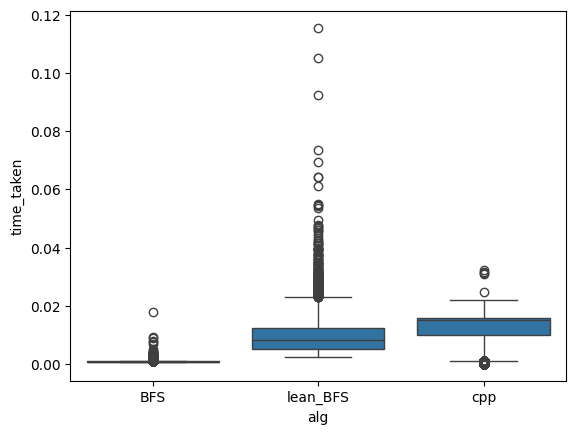

In [17]:
sns.boxplot(data=r[r.alg != 'DFS'], x='alg', y='time_taken')

In [18]:
unyts.dictionaries.dictionary

{'Time': ('mo',
  'yyyy',
  'Ts',
  'CENTURY',
  'h',
  'CENTURIES',
  'centurys',
  'decades',
  'MES',
  'hh',
  'WEEKS',
  'µs',
  'YY',
  'day',
  'qs',
  'LUSTRUM',
  'lustrums',
  'rs',
  'seconds',
  'YYYY',
  'DECADE',
  'ds',
  'años',
  'Ms',
  'Ps',
  'MIN',
  'WEEK',
  'MONTH',
  'DÍA',
  'days',
  'MONTHS',
  'HOUR',
  'hour',
  'us',
  'weeks',
  'MINUTE',
  'HH',
  'SS',
  'lustrum',
  'week',
  'nanosecond',
  'MINS',
  'Ys',
  'NANOSECOND',
  'cs',
  'minute',
  'DÍAS',
  'Rs',
  'NANOSECONDS',
  'Wh/W',
  'min',
  'ms',
  'yy',
  'LUSTRUMS',
  'AÑO',
  'hr',
  'das',
  'century',
  'DECADES',
  'MINUTES',
  'fs',
  'HR',
  'S',
  'SEC',
  'hs',
  'WATT HOUR/WATT',
  'Es',
  'MO',
  'ys',
  'nanoseconds',
  'WE',
  'month',
  'mins',
  'decade',
  'meses',
  'WH/W',
  'AÑOS',
  'YEARS',
  'ks',
  'sec',
  'd',
  'MS',
  'HOURS',
  'years',
  'DAYS',
  'Gs',
  'second',
  'zs',
  'SECOND',
  'ss',
  'Ks',
  'CENTURYS',
  'milliseconds',
  'year',
  'MILLISECOND',
  'y',

In [20]:
r[r.alg == 'BFS'].sort_values(by='time_taken', ascending=False)

,time_taken,error,key,from_unit,to_unit,alg,ite,from_to
28380,0.025268,False,Time,día,CENTURY,BFS,0,día->CENTURY
77148,0.012753,False,Time,years,nanosecond,BFS,3,years->nanosecond
77146,0.011663,False,Time,years,nanosecond,BFS,1,years->nanosecond
77177,0.010909,False,Time,years,WE,BFS,2,years->WE
77175,0.009266,False,Time,years,WE,BFS,0,years->WE
...,...,...,...,...,...,...,...,...
134509,0.000028,False,TemperatureGradient,"deg C/""",degrees C/chain,BFS,4,"deg C/""->degrees C/chain"
131224,0.000028,False,TemperatureGradient,"deg C/""",degC/Qm,BFS,4,"deg C/""->degC/Qm"
135199,0.000028,False,TemperatureGradient,"deg C/""",Fahrenheit/parsec,BFS,4,"deg C/""->Fahrenheit/parsec"
135034,0.000028,False,TemperatureGradient,"deg C/""",degrees F/ROD,BFS,4,"deg C/""->degrees F/ROD"


In [21]:
unyts.convert(365, 'días', 'CENTURY')

0.00999315537303217